
# Heart Disease Prediction Using Machine Learning

## Introduction

This project aims to reproduce the experiment presented in the research paper *"Evaluating Logistic Regression, SVM, KNN, and Ensemble Models for Accurate Heart Disease Risk Prediction"* by Amalia Shifa Aldila and Lawrence Adi Supriyono (2026).

The original study evaluates six supervised machine learning classification algorithms using the Cleveland Heart Disease Dataset from the UCI Machine Learning Repository.

For this midterm project, we will focus on reproducing the experiment using four classification algorithms:

1. Logistic Regression
2. K-Nearest Neighbors (KNN)
3. Support Vector Machine (SVM)
4. Decision Tree

The project will follow the research paper's methodology, including Exploratory Data Analysis (EDA), data preprocessing, feature preparation, model training, hyperparameter tuning, and performance evaluation.

The models will be evaluated using Accuracy, Precision, Recall, F1 Score, and ROC-AUC to compare their predictive performance with the results reported in the original research.

## Project Objective

To reproduce and compare four supervised machine learning classification algorithms for predicting the presence or absence of heart disease using the Cleveland Heart Disease Dataset, and evaluate how closely our results match those reported by Aldila and Supriyono (2026).



## Table of Contents

### Introduction
Research Paper Overview
Project Objective
Dataset Description


# Table of Contents

## Phase 1 — Exploratory Data Analysis (EDA) & Data Preprocessing

1. Import Libraries
2. Load Dataset
   - 2.1 Dataset Feature Description
3. Dataset Overview
   - 3.1 Dataset Shape
   - 3.2 Column Names and Data Types
   - 3.3 Dataset Information
   - 3.4 Descriptive Statistics
   - 3.5 Initial Dataset Findings
4. Data Quality Assessment
   - 4.1 Missing Values
   - 4.2 Duplicate Records
   - 4.3 Outlier Detection
5. Exploratory Data Analysis (EDA)
   - 5.1 Target Distribution
   - 5.2 Numerical Feature Distributions
   - 5.3 Categorical Feature Analysis
   - 5.4 Correlation Analysis
6. Data Preprocessing
   - 6.1 Binary Target Transformation
   - 6.2 Missing Value Treatment
   - 6.3 Feature Encoding

---

## Phase 2 — Model Training

7. Feature and Target Selection
8. Train/Test Split (80/20)
9. Feature Scaling — Min-Max Normalization (0–10)
10. Classification Models
    - 10.1 Logistic Regression
    - 10.2 K-Nearest Neighbors (KNN)
    - 10.3 Support Vector Machine (SVM)
    - 10.4 Decision Tree
11. Hyperparameter Tuning — GridSearchCV
12. Six-Fold Cross-Validation

---

## Phase 3 — Model Evaluation & Comparison

13. Model Performance Evaluation
    - 13.1 Accuracy
    - 13.2 Precision
    - 13.3 Recall (Sensitivity)
    - 13.4 F1 Score
    - 13.5 Specificity
    - 13.6 Confusion Matrix
14. ROC Curves and AUC Scores
15. Model Performance Comparison
16. Comparison with the Research Paper
17. Suggested Improvements
18. Conclusions




# Phase 1 — Exploratory Data Analysis (EDA) & Data Preprocessing

## 1. Import Libraries


In [1]:

# Data manipulation
import pandas as pd
import numpy as np

# Data visualization
import matplotlib.pyplot as plt
import seaborn as sns

# Display settings
pd.set_option("display.max_columns", None)
pd.set_option("display.width", 1000)



## 2. Load Dataset

The Cleveland Heart Disease Dataset is used to analyze clinical features and predict the presence or absence of heart disease.

The dataset contains 303 observations and 14 attributes, including the target variable.


In [2]:

# Load dataset
df = pd.read_csv("heart_cleveland.csv", na_values="?")

# Display the first 5 observations
display(df.head())


,age,sex,cp,trestbps,chol,fbs,restecg,thalach,exang,oldpeak,slope,ca,thal,num
0,63.0,1.0,1.0,145.0,233.0,1.0,2.0,150.0,0.0,2.3,3.0,0.0,6.0,0
1,67.0,1.0,4.0,160.0,286.0,0.0,2.0,108.0,1.0,1.5,2.0,3.0,3.0,2
2,67.0,1.0,4.0,120.0,229.0,0.0,2.0,129.0,1.0,2.6,2.0,2.0,7.0,1
3,37.0,1.0,3.0,130.0,250.0,0.0,0.0,187.0,0.0,3.5,3.0,0.0,3.0,0
4,41.0,0.0,2.0,130.0,204.0,0.0,2.0,172.0,0.0,1.4,1.0,0.0,3.0,0



### 2.1 Dataset Feature Description

The Cleveland Heart Disease Dataset contains 303 patient records, 13 input features, and 1 target variable.

The following table describes each feature, its medical meaning, and the values used in the dataset.

| Feature | Medical Term | Description | Values / Units |
|---|---|---|---|
| **age** | Age | Patient's age. | Years |
| **sex** | Biological Sex | Patient's recorded sex. | 0 = Female, 1 = Male |
| **cp** | Chest Pain Type | Type of chest pain experienced by the patient. | 1 = Typical Angina; 2 = Atypical Angina; 3 = Non-anginal Pain; 4 = Asymptomatic |
| **trestbps** | Resting Blood Pressure | Blood pressure measured while the patient is at rest. | mm Hg |
| **chol** | Serum Cholesterol | Amount of cholesterol in the patient's blood. | mg/dL |
| **fbs** | Fasting Blood Sugar | Indicates whether fasting blood sugar exceeds 120 mg/dL. | 0 = No, 1 = Yes |
| **restecg** | Resting Electrocardiogram | Results of an ECG, which measures the electrical activity of the heart. | 0 = Normal; 1 = ST-T Wave Abnormality; 2 = Left Ventricular Hypertrophy |
| **thalach** | Maximum Heart Rate | Highest heart rate achieved during exercise testing. | Beats per minute (bpm) |
| **exang** | Exercise-Induced Angina | Indicates whether exercise causes chest pain associated with reduced blood flow to the heart. | 0 = No, 1 = Yes |
| **oldpeak** | ST Depression | Measurement of changes in the heart's electrical activity during exercise compared with rest. | Numeric ST depression value |
| **slope** | Slope of the ST Segment | Direction of the ST segment during peak exercise. | 1 = Upsloping; 2 = Flat; 3 = Downsloping |
| **ca** | Major Vessels | Number of major coronary vessels highlighted by fluoroscopy (X-ray imaging). | 0–3 |
| **thal** | Thalassemia / Thallium Test Result | Encoded result of a heart perfusion test, indicating normal blood flow or a fixed/reversible defect. | 3 = Normal; 6 = Fixed Defect; 7 = Reversible Defect |
| **num** | Heart Disease Diagnosis (Target) | Indicates the presence or absence of heart disease. | Original: 0–4; Binary: 0 = No Disease, 1 = Disease |

**Note:** The original target values 1–4 represent the presence of heart disease. For binary classification, these values will be grouped into class 1.



## 3. Dataset Overview

This section provides an initial overview of the Cleveland Heart Disease Dataset, including its dimensions, column names, data types, and descriptive statistics.

The objective is to understand the dataset structure before performing data cleaning and preprocessing.



### 3.1 Dataset Shape


In [3]:

# Dataset dimensions
print("Number of rows:", df.shape[0])
print("Number of columns:", df.shape[1])


Number of rows: 303
Number of columns: 14



### 3.2 Column Names and Data Types


In [5]:

# Display column names and data types
column_info = pd.DataFrame({
    "Column": df.columns,
    "Data Type": df.dtypes.astype(str).values
})

display(column_info)


,Column,Data Type
0,age,float64
1,sex,float64
2,cp,float64
3,trestbps,float64
4,chol,float64
5,fbs,float64
6,restecg,float64
7,thalach,float64
8,exang,float64
9,oldpeak,float64



### 3.3 Dataset Information


In [6]:

# General dataset information
df.info()


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 303 entries, 0 to 302
Data columns (total 14 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   age       303 non-null    float64
 1   sex       303 non-null    float64
 2   cp        303 non-null    float64
 3   trestbps  303 non-null    float64
 4   chol      303 non-null    float64
 5   fbs       303 non-null    float64
 6   restecg   303 non-null    float64
 7   thalach   303 non-null    float64
 8   exang     303 non-null    float64
 9   oldpeak   303 non-null    float64
 10  slope     303 non-null    float64
 11  ca        299 non-null    float64
 12  thal      301 non-null    float64
 13  num       303 non-null    int64  
dtypes: float64(13), int64(1)
memory usage: 33.3 KB



### 3.4 Descriptive Statistics


In [7]:

# Descriptive statistics for all columns
display(df.describe(include="all").T)


,count,mean,std,min,25%,50%,75%,max
age,303.0,54.438944,9.038662,29.0,48.0,56.0,61.0,77.0
sex,303.0,0.679868,0.467299,0.0,0.0,1.0,1.0,1.0
cp,303.0,3.158416,0.960126,1.0,3.0,3.0,4.0,4.0
trestbps,303.0,131.689769,17.599748,94.0,120.0,130.0,140.0,200.0
chol,303.0,246.693069,51.776918,126.0,211.0,241.0,275.0,564.0
fbs,303.0,0.148515,0.356198,0.0,0.0,0.0,0.0,1.0
restecg,303.0,0.990099,0.994971,0.0,0.0,1.0,2.0,2.0
thalach,303.0,149.607261,22.875003,71.0,133.5,153.0,166.0,202.0
exang,303.0,0.326733,0.469794,0.0,0.0,0.0,1.0,1.0
oldpeak,303.0,1.039604,1.161075,0.0,0.0,0.8,1.6,6.2



### 3.5 Initial Dataset Findings

The Cleveland Heart Disease Dataset contains 303 observations and 14 columns, including 13 input features and one target variable (`num`).

All columns are stored as numerical data types (`float64` or `int64`). However, some features represent categorical medical information encoded as numbers.

The descriptive statistics reveal:

- The average patient age is approximately 54.44 years.
- Approximately 68% of patients are male.
- The average resting blood pressure is 131.69 mm Hg.
- The average serum cholesterol level is 246.69 mg/dL.
- The dataset contains 6 missing values: 4 in `ca` and 2 in `thal`.
- The target variable (`num`) contains values from 0 to 4 and will be converted into binary classes for classification.

These findings provide an initial understanding of the dataset and identify the main preprocessing requirements.



## 4. Data Quality Assessment

This section examines missing values, duplicate records, and potential outliers to assess data quality before preprocessing.

### 4.1 Missing Values

Missing values are identified and quantified for each feature before selecting an appropriate treatment method.


In [8]:

# Missing values by feature
missing_summary = pd.DataFrame({
    "Missing Values": df.isnull().sum(),
    "Missing Percentage (%)": (df.isnull().mean() * 100).round(2)
})

display(missing_summary)

# Total missing values
print("Total Missing Values:", df.isnull().sum().sum())

# Display observations containing missing values
display(df[df.isnull().any(axis=1)])


,Missing Values,Missing Percentage (%)
age,0,0.00
sex,0,0.00
cp,0,0.00
trestbps,0,0.00
chol,0,0.00
fbs,0,0.00
restecg,0,0.00
thalach,0,0.00
exang,0,0.00
oldpeak,0,0.00


Total Missing Values: 6


,age,sex,cp,trestbps,chol,fbs,restecg,thalach,exang,oldpeak,slope,ca,thal,num
87,53.0,0.0,3.0,128.0,216.0,0.0,2.0,115.0,0.0,0.0,1.0,0.0,NaN,0
166,52.0,1.0,3.0,138.0,223.0,0.0,0.0,169.0,0.0,0.0,1.0,NaN,3.0,0
192,43.0,1.0,4.0,132.0,247.0,1.0,2.0,143.0,1.0,0.1,2.0,NaN,7.0,1
266,52.0,1.0,4.0,128.0,204.0,1.0,0.0,156.0,1.0,1.0,2.0,0.0,NaN,2
287,58.0,1.0,2.0,125.0,220.0,0.0,0.0,144.0,0.0,0.4,2.0,NaN,7.0,0
302,38.0,1.0,3.0,138.0,175.0,0.0,0.0,173.0,0.0,0.0,1.0,NaN,3.0,0



### 4.2 Duplicate Records

Duplicate records are checked to identify repeated observations that could affect the reliability of the analysis.


In [9]:

# Count duplicate records
duplicate_count = df.duplicated().sum()

print("Total Duplicate Records:", duplicate_count)

# Display duplicate records, if any
display(df[df.duplicated(keep=False)])


Total Duplicate Records: 0


,age,sex,cp,trestbps,chol,fbs,restecg,thalach,exang,oldpeak,slope,ca,thal,num



### Data Quality Findings

The initial data quality assessment identified 6 missing values across 6 patient records (1.98% of the dataset).

- `ca`: 4 missing values (1.32%).
- `thal`: 2 missing values (0.66%).
- All remaining features contain no missing values.
- No duplicate records were detected.

To reproduce the methodology described in Aldila and Supriyono (2026), observations containing missing clinical values will be removed during the preprocessing stage.

After removing incomplete observations, the dataset is expected to contain 297 patient records.



### 4.3 Outlier Detection

Outliers are examined using boxplots and the Interquartile Range (IQR) method.

The objective is to identify unusually high or low values in continuous numerical features without automatically removing clinically relevant observations.


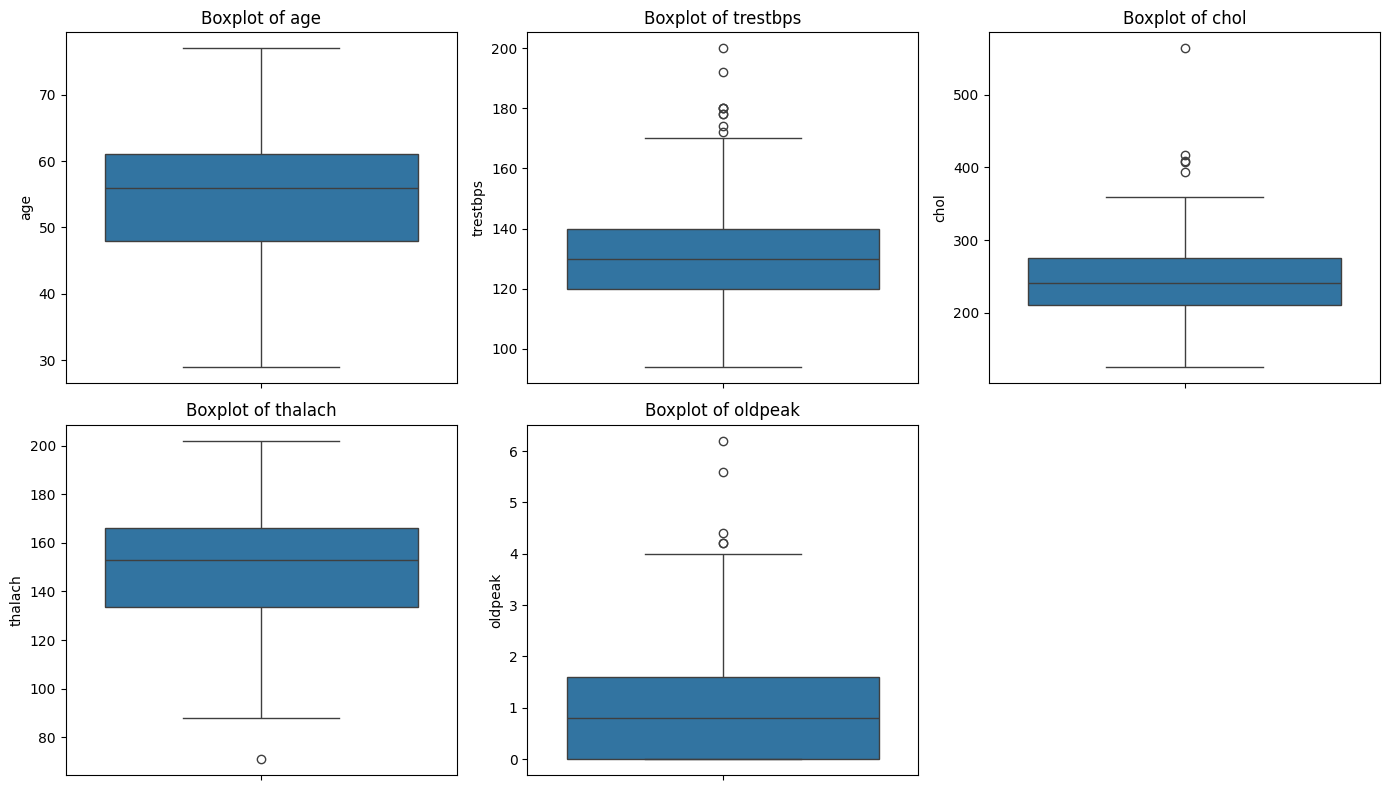

In [10]:

# Continuous numerical features
numerical_features = [
    "age", "trestbps", "chol",
    "thalach", "oldpeak"
]

# Boxplots for outlier detection
plt.figure(figsize=(14, 8))

for i, feature in enumerate(numerical_features, 1):
    plt.subplot(2, 3, i)
    sns.boxplot(y=df[feature])
    plt.title(f"Boxplot of {feature}")

plt.tight_layout()
plt.show()


In [11]:

# Detect potential outliers using the IQR method
outlier_results = []

for feature in numerical_features:
    Q1 = df[feature].quantile(0.25)
    Q3 = df[feature].quantile(0.75)

    IQR = Q3 - Q1

    lower_bound = Q1 - 1.5 * IQR
    upper_bound = Q3 + 1.5 * IQR

    outlier_count = (
        (df[feature] < lower_bound) |
        (df[feature] > upper_bound)
    ).sum()

    outlier_results.append({
        "Feature": feature,
        "Lower Bound": round(lower_bound, 2),
        "Upper Bound": round(upper_bound, 2),
        "Outlier Count": outlier_count
    })

outlier_summary = pd.DataFrame(outlier_results)

display(outlier_summary)


,Feature,Lower Bound,Upper Bound,Outlier Count
0,age,28.50,80.50,0
1,trestbps,90.00,170.00,9
2,chol,115.00,371.00,5
3,thalach,84.75,214.75,1
4,oldpeak,-2.40,4.00,5



### 4.3.1 Outlier Analysis Findings

The IQR method identified the following potential outliers:

- Age: 0 outliers.
- Resting Blood Pressure (`trestbps`): 9 outliers.
- Serum Cholesterol (`chol`): 5 outliers.
- Maximum Heart Rate (`thalach`): 1 outlier.
- ST Depression (`oldpeak`): 5 outliers.

A total of 20 feature-level outlier occurrences were identified.

These observations may represent clinically relevant patient conditions rather than data entry errors.

Following the research methodology, outliers will be retained to preserve potentially important medical information.



## 5. Exploratory Data Analysis (EDA)

This section explores the distribution of patient characteristics and their relationship with heart disease diagnosis.

### 5.1 Target Distribution

The original target variable (`num`) contains five diagnostic categories ranging from 0 to 4.

Before transforming the target into binary classification, its original distribution is examined.


num
0    164
1     55
2     36
3     35
4     13
Name: count, dtype: int64

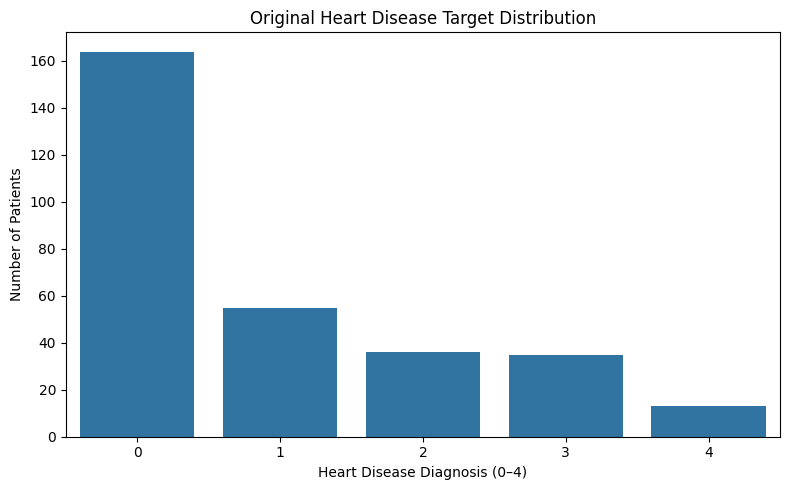

In [13]:

# Target distribution
target_counts = df["num"].value_counts().sort_index()

display(target_counts)

# Visualize target distribution
plt.figure(figsize=(8, 5))

sns.countplot(
    data=df,
    x="num",
    order=sorted(df["num"].unique())
)

plt.title("Original Heart Disease Target Distribution")
plt.xlabel("Heart Disease Diagnosis (0–4)")
plt.ylabel("Number of Patients")

plt.tight_layout()
plt.show()



### 5.1.1 Target Distribution Findings

The original target variable (`num`) contains five categories (0–4).

- Class 0: 164 patients (54.13%) without heart disease.
- Classes 1–4: 139 patients (45.87%) with heart disease.

For binary classification, categories 1–4 will be combined into a single positive class (1), while category 0 will remain the negative class.

The resulting class distribution is relatively balanced, with no substantial class imbalance observed.

The class distribution will be reassessed after missing-value treatment.



### 5.2 Numerical Feature Distributions

Histograms are used to examine the distribution of continuous numerical features.

This analysis helps identify common value ranges, skewness, and unusual patterns in patient characteristics.


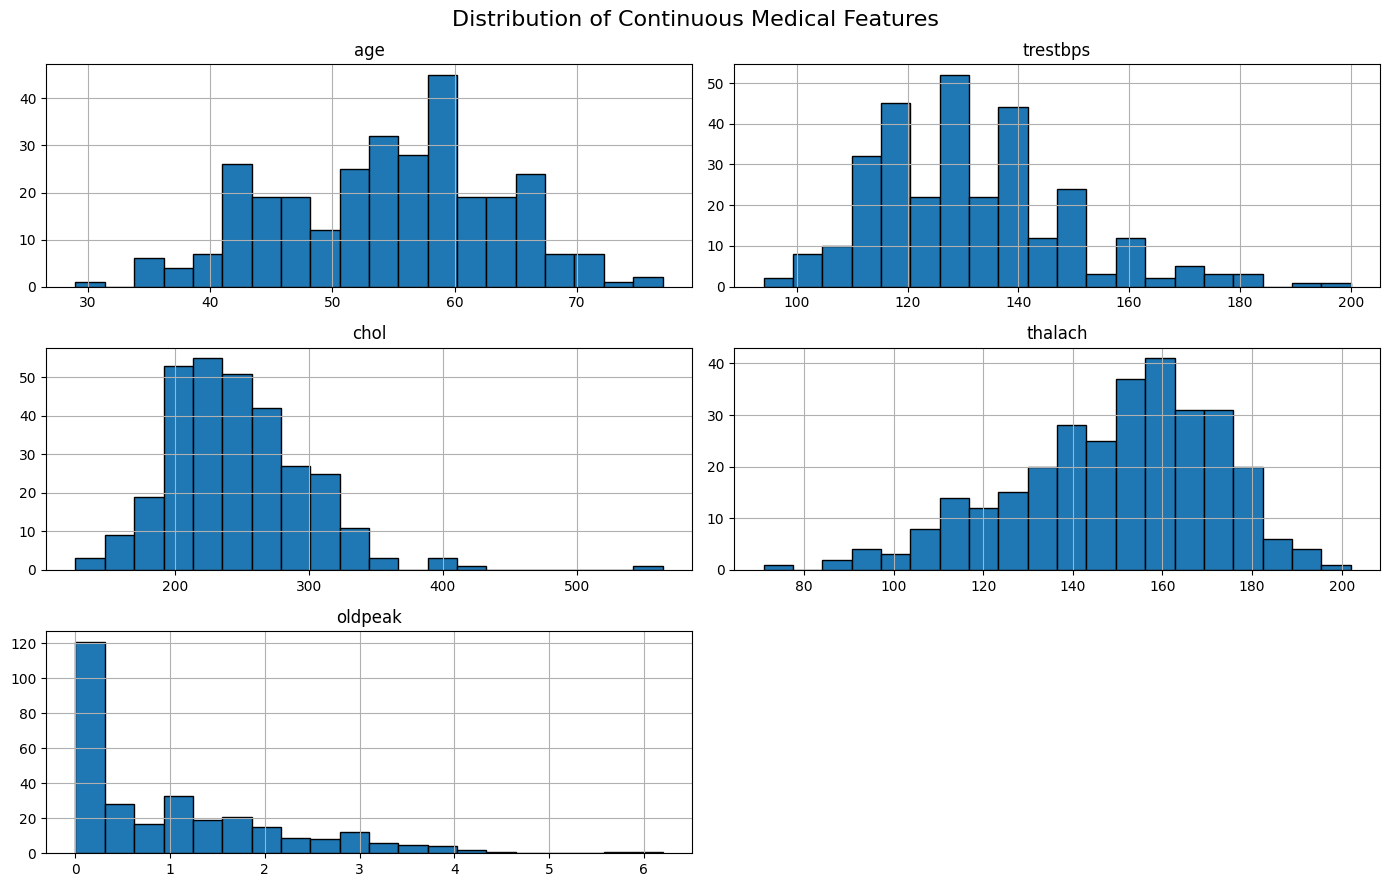

In [14]:

# Continuous numerical features
numerical_features = [
    "age", "trestbps", "chol",
    "thalach", "oldpeak"
]

# Plot histograms
df[numerical_features].hist(
    figsize=(14, 9),
    bins=20,
    edgecolor="black"
)

plt.suptitle(
    "Distribution of Continuous Medical Features",
    fontsize=16
)

plt.tight_layout()
plt.show()



### 5.2.1 Numerical Feature Distribution Findings

The histograms reveal different distribution patterns across the continuous medical features:

- **Age:** Approximately bell-shaped distribution, with most patients between 40 and 65 years old.
- **Resting Blood Pressure (`trestbps`):** Slightly right-skewed distribution, with most values between 110 and 145 mm Hg.
- **Serum Cholesterol (`chol`):** Right-skewed distribution with several unusually high values.
- **Maximum Heart Rate (`thalach`):** Left-skewed distribution, with most values concentrated between 140 and 180 bpm.
- **ST Depression (`oldpeak`):** Strongly right-skewed distribution, with many observations close to zero.

**Conclusion:** The continuous features show different ranges, distributions, and potential outliers. Feature scaling will be considered during model training, following the methodology described in the research paper.

Potential outliers will be retained because they may represent clinically relevant observations.



### 5.3 Categorical Feature Analysis

This section examines the frequency distribution of categorical and discrete medical features.

Although these features are numerically encoded, their values represent categories or discrete clinical measurements rather than continuous quantities.


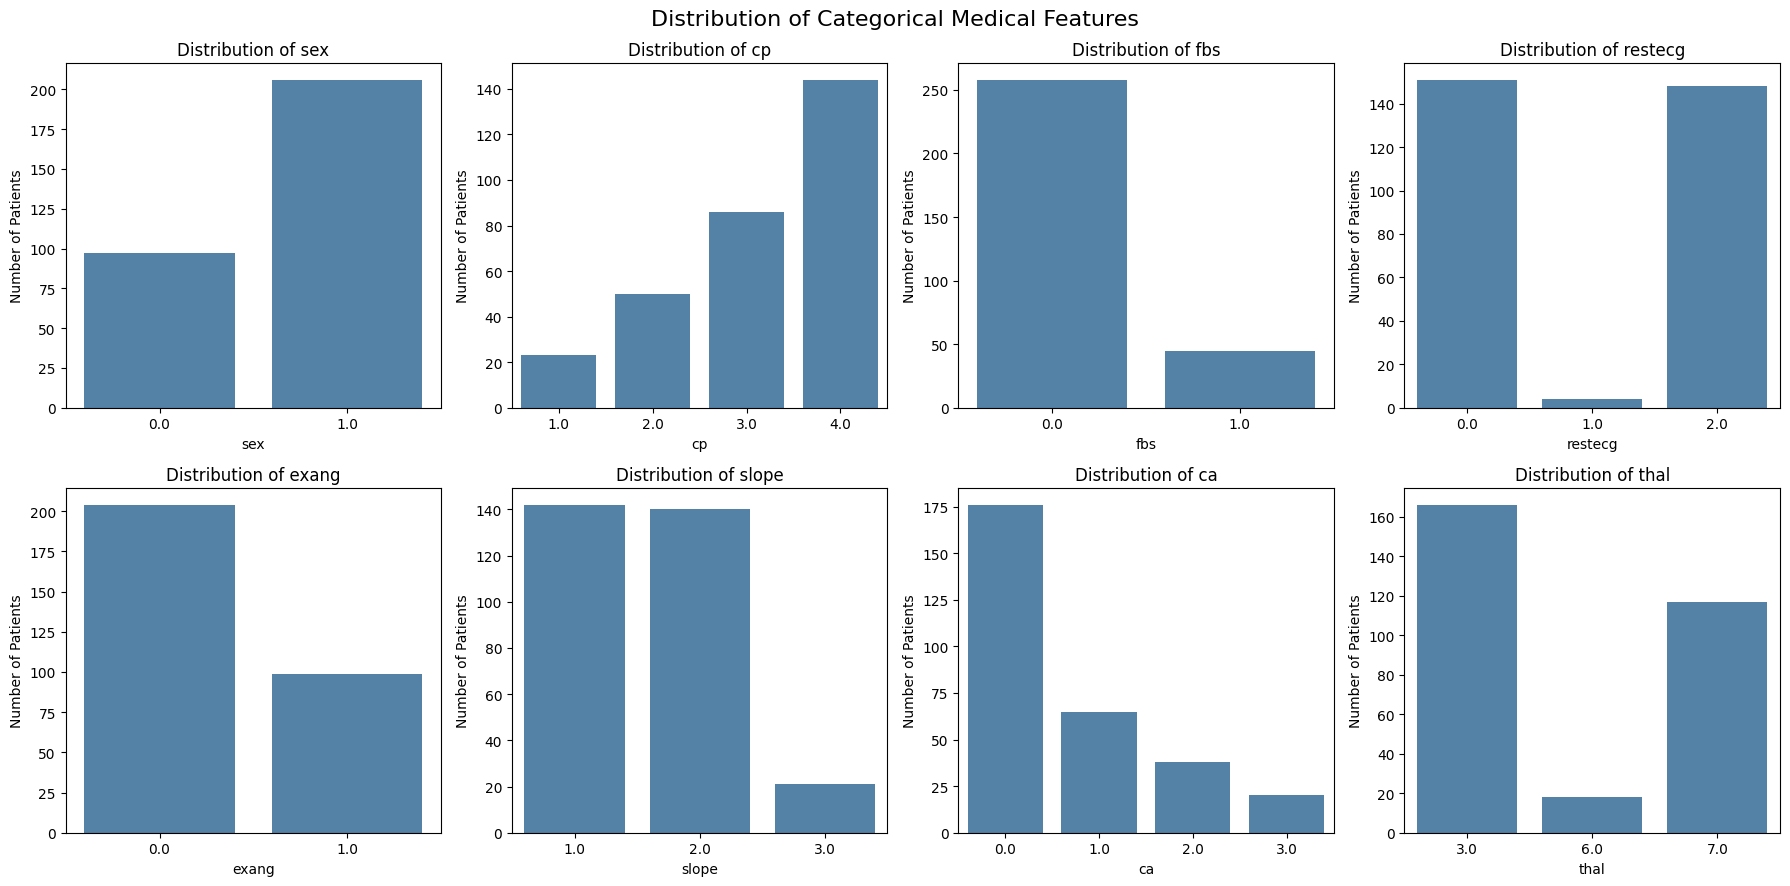

In [15]:

# Categorical and discrete features
categorical_features = [
    "sex", "cp", "fbs", "restecg",
    "exang", "slope", "ca", "thal"
]

# Plot categorical distributions
fig, axes = plt.subplots(2, 4, figsize=(18, 9))

for ax, feature in zip(axes.flat, categorical_features):
    sns.countplot(
        data=df,
        x=feature,
        ax=ax,
        color="steelblue"
    )

    ax.set_title(f"Distribution of {feature}")
    ax.set_xlabel(feature)
    ax.set_ylabel("Number of Patients")

plt.suptitle(
    "Distribution of Categorical Medical Features",
    fontsize=16
)

plt.tight_layout()
plt.show()


In [16]:

# Frequency distribution of categorical features
for feature in categorical_features:
    print(f"\nFeature: {feature}")

    frequency_table = pd.DataFrame({
        "Count": df[feature].value_counts(dropna=False),
        "Percentage (%)": (
            df[feature].value_counts(
                normalize=True,
                dropna=False
            ) * 100
        ).round(2)
    })

    display(frequency_table.sort_index())



Feature: sex


,Count,Percentage (%)
sex,,
0.0,97,32.01
1.0,206,67.99



Feature: cp


,Count,Percentage (%)
cp,,
1.0,23,7.59
2.0,50,16.50
3.0,86,28.38
4.0,144,47.52



Feature: fbs


,Count,Percentage (%)
fbs,,
0.0,258,85.15
1.0,45,14.85


... (6 outputs left out)


Feature: ca


,Count,Percentage (%)
ca,,
0.0,176,58.09
1.0,65,21.45
2.0,38,12.54
3.0,20,6.60
NaN,4,1.32



Feature: thal


,Count,Percentage (%)
thal,,
3.0,166,54.79
6.0,18,5.94
7.0,117,38.61
NaN,2,0.66



### 5.3.1 Categorical Feature Analysis Findings

The categorical feature analysis examines the frequency distribution of eight categorical and discrete medical variables: `sex`, `cp`, `fbs`, `restecg`, `exang`, `slope`, `ca`, and `thal`.

**Key Observations:**

- The features are numerically encoded but represent medical categories or discrete measurements.
- Frequency distributions help identify the most and least common categories.
- The features `ca` and `thal` contain missing values, which will be addressed during preprocessing.
- Categorical encoding requirements will be evaluated before model training.

**Conclusion:**

Understanding categorical feature distributions helps identify patterns in patient characteristics and supports appropriate data preprocessing decisions.



### 5.4 Correlation Analysis

Correlation analysis is used to explore linear relationships between numerical medical features and the target variable.

Pearson correlation coefficients range from -1 to +1:

- **+1:** Perfect positive linear correlation.
- **-1:** Perfect negative linear correlation.
- **0:** No linear correlation.

This analysis helps identify potentially related features and possible multicollinearity.

**Note:** Correlations involving numerically encoded categorical variables should be interpreted with caution.


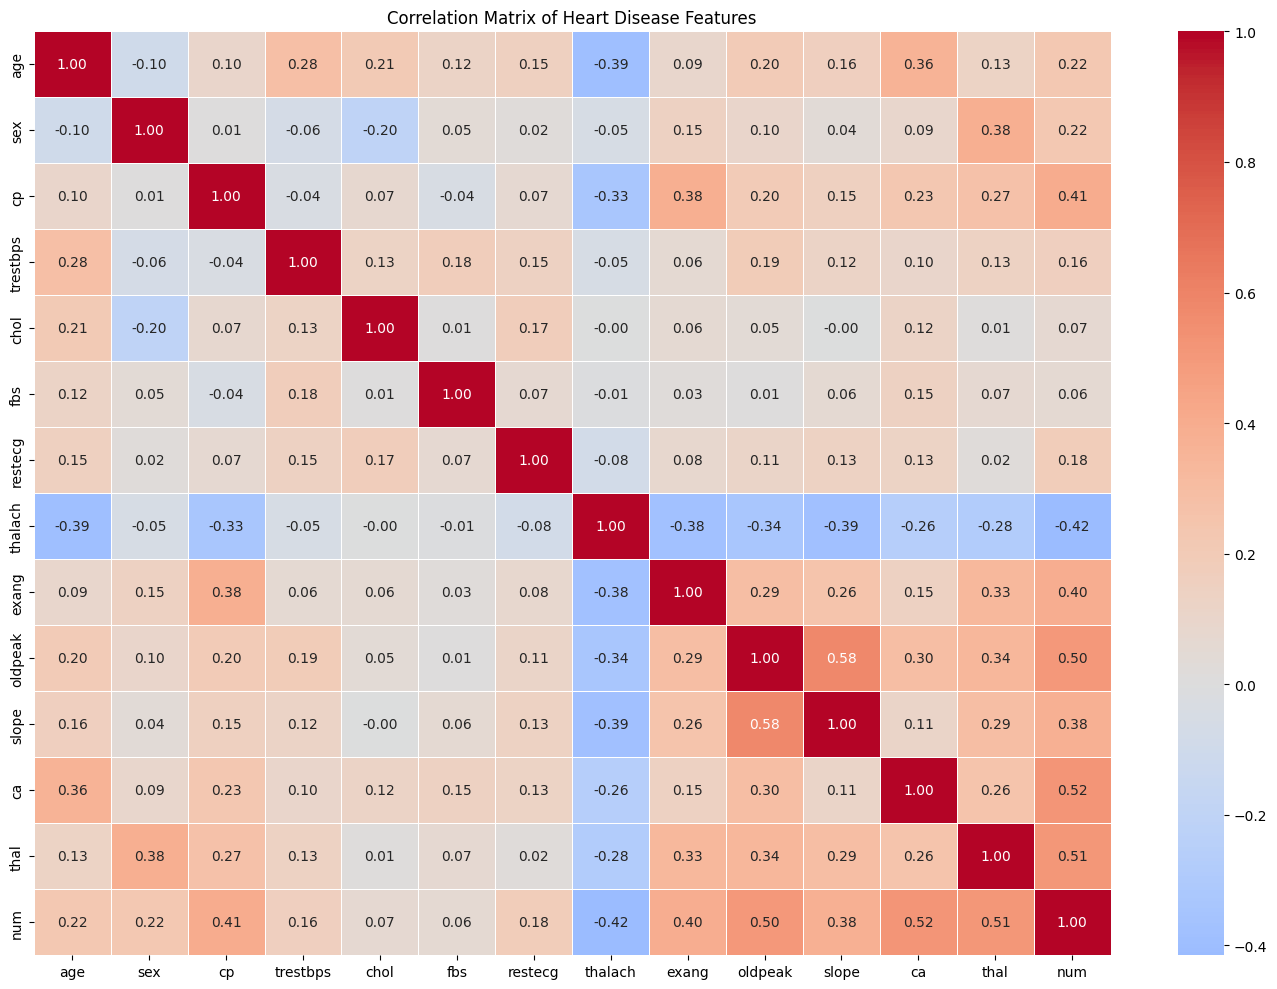

In [17]:

# Calculate Pearson correlation matrix
corr_matrix = df.corr(method="pearson")

# Plot correlation heatmap
plt.figure(figsize=(14, 10))

sns.heatmap(
    corr_matrix,
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    center=0,
    linewidths=0.5
)

plt.title("Correlation Matrix of Heart Disease Features")
plt.tight_layout()
plt.show()


In [19]:

# Separate input features from target
X_original = df.drop(columns="num")

# Calculate absolute correlation values
corr_abs = X_original.corr().abs()

# Keep only the upper triangle to avoid duplicate pairs
upper_triangle = corr_abs.where(
    np.triu(np.ones(corr_abs.shape), k=1).astype(bool)
)

# Sort feature pairs by correlation strength
strong_pairs = upper_triangle.stack().sort_values(
    ascending=False
)

# Display the 15 strongest correlated pairs
display(strong_pairs.head(15))


oldpeak  slope       0.577537
age      thalach     0.393806
thalach  slope       0.385601
cp       exang       0.384060
sex      thal        0.380936
thalach  exang       0.378103
age      ca          0.362605
thalach  oldpeak     0.343085
oldpeak  thal        0.341004
cp       thalach     0.334422
exang    thal        0.329680
oldpeak  ca          0.295832
exang    oldpeak     0.288223
slope    thal        0.287232
age      trestbps    0.284946
dtype: float64

,Correlation with Heart Disease
thalach,-0.417167
fbs,0.025264
chol,0.085164
trestbps,0.150825
restecg,0.169202
age,0.223120
sex,0.276816
slope,0.339213
cp,0.414446
oldpeak,0.424510


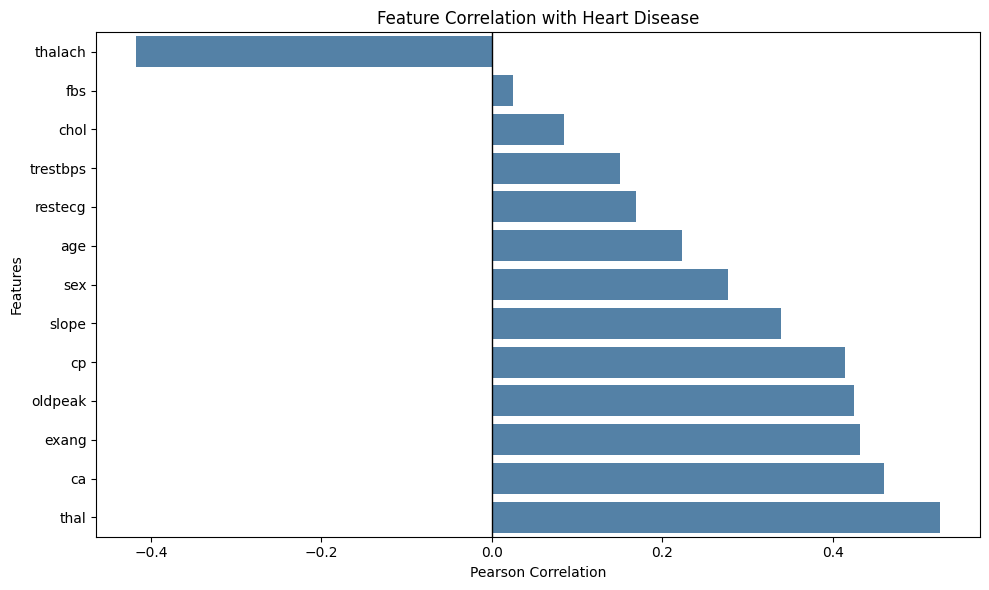

In [20]:

# Create a temporary binary target for exploratory analysis
target_binary = (df["num"] > 0).astype(int)

# Calculate feature correlations with binary target
target_correlation = X_original.corrwith(
    target_binary
).sort_values()

# Display correlations
display(
    target_correlation.to_frame(
        name="Correlation with Heart Disease"
    )
)

# Visualize correlations
plt.figure(figsize=(10, 6))

sns.barplot(
    x=target_correlation.values,
    y=target_correlation.index,
    color="steelblue"
)

plt.title("Feature Correlation with Heart Disease")
plt.xlabel("Pearson Correlation")
plt.ylabel("Features")
plt.axvline(0, color="black", linewidth=1)

plt.tight_layout()
plt.show()



### 5.4.1 Correlation Analysis Findings

Pearson correlation analysis was performed to examine relationships between medical features and the binary heart disease target.

**Correlation Between Features:**

- `oldpeak` and `slope` showed the strongest absolute correlation (0.578).
- `age` and `thalach` showed an absolute correlation of 0.394.
- No extremely high pairwise correlations (|r| ≥ 0.90) were identified.

**Correlation with Heart Disease:**

The strongest observed associations with the binary target were:

- `thal`: +0.526
- `ca`: +0.460
- `exang`: +0.432
- `oldpeak`: +0.425
- `thalach`: -0.417
- `cp`: +0.414

**Key Findings:**

- `thal` showed the strongest positive correlation with heart disease.
- `thalach` showed the strongest negative correlation.
- Several medical features demonstrated moderate associations with the target variable.

**Conclusion:**

The analysis identified potentially informative features for heart disease classification.

However, correlation does not imply causation, and Pearson correlations involving numerically encoded categorical variables must be interpreted cautiously.

All 13 input features will initially be retained for model development.



## 6. Data Preprocessing

This section prepares the dataset for binary classification by transforming the target variable, handling missing values, and reviewing categorical feature encoding.

### 6.1 Binary Target Transformation

The original target variable (`num`) contains five categories ranging from 0 to 4.

To reproduce the binary classification approach used in the research paper, the target will be transformed into two classes:

- **0:** No Heart Disease
- **1:** Heart Disease Present (original values 1–4)

A separate copy of the dataset will be created to preserve the original data.


In [25]:

# Create a copy of the original dataset
df_clean = df.copy()

# Convert target into binary classification
df_clean["num"] = (df_clean["num"] > 0).astype(int)

# Display binary target distribution
print("Binary Target Distribution:")
display(df_clean["num"].value_counts().sort_index())

# Verify target values
print("Unique Target Values:", df_clean["num"].unique())


Binary Target Distribution:


num
0    164
1    139
Name: count, dtype: int64

Unique Target Values: [0 1]


In [26]:

# Compare original and transformed target
print("Original Target:")
print(sorted(df["num"].unique()))

print("\nBinary Target:")
print(sorted(df_clean["num"].unique()))


Original Target:
[np.int64(0), np.int64(1), np.int64(2), np.int64(3), np.int64(4)]

Binary Target:
[np.int64(0), np.int64(1)]



### 6.2 Missing Value Treatment

The dataset contains six missing values distributed across two medical features:

- `ca`: 4 missing values.
- `thal`: 2 missing values.

Following the research paper's preprocessing approach, incomplete observations will be removed using listwise deletion.

This method preserves complete patient records for model training and evaluation.


In [27]:

# Check dataset shape before cleaning
print("Original Shape:", df_clean.shape)

# Remove rows containing missing values
df_clean = df_clean.dropna().copy()

# Verify dataset shape after cleaning
print("Cleaned Shape:", df_clean.shape)

# Verify remaining missing values
print("Remaining Missing Values:", df_clean.isnull().sum().sum())


Original Shape: (303, 14)
Cleaned Shape: (297, 14)
Remaining Missing Values: 0


In [28]:

# Verify class distribution after cleaning
class_distribution = pd.DataFrame({
    "Count": df_clean["num"].value_counts().sort_index(),
    "Percentage (%)": (
        df_clean["num"].value_counts(normalize=True).sort_index() * 100
    ).round(2)
})

display(class_distribution)


,Count,Percentage (%)
num,,
0,160,53.87
1,137,46.13



### 6.2.1 Missing Value Treatment Findings

Six incomplete patient records were removed from the dataset.

- Original dataset: 303 observations.
- Cleaned dataset: 297 observations.
- Removed observations: 6 (1.98%).
- Remaining missing values: 0.

The cleaned dataset retains all 14 columns and is ready for categorical feature encoding.



### 6.3 Feature Encoding

The Cleveland Heart Disease Dataset contains categorical features that are already represented by numerical codes.

To reproduce the original research methodology, the existing numerical encoding will be retained for the initial experiments.

One-Hot Encoding may be evaluated later as a potential improvement, particularly for nominal categorical features.


In [30]:

# Categorical and discrete features
categorical_features = [
    "sex", "cp", "fbs", "restecg",
    "exang", "slope", "ca", "thal"
]

# Check unique values after cleaning
for feature in categorical_features:
    print(f"{feature}: {sorted(df_clean[feature].unique())}")


sex: [np.float64(0.0), np.float64(1.0)]
cp: [np.float64(1.0), np.float64(2.0), np.float64(3.0), np.float64(4.0)]
fbs: [np.float64(0.0), np.float64(1.0)]
restecg: [np.float64(0.0), np.float64(1.0), np.float64(2.0)]
exang: [np.float64(0.0), np.float64(1.0)]
slope: [np.float64(1.0), np.float64(2.0), np.float64(3.0)]
ca: [np.float64(0.0), np.float64(1.0), np.float64(2.0), np.float64(3.0)]
thal: [np.float64(3.0), np.float64(6.0), np.float64(7.0)]


In [31]:

# Verify final dataset structure
print("Cleaned Dataset Shape:", df_clean.shape)
print("Missing Values:", df_clean.isnull().sum().sum())
print("Duplicate Records:", df_clean.duplicated().sum())

# Preview cleaned dataset
display(df_clean.head())


Cleaned Dataset Shape: (297, 14)
Missing Values: 0
Duplicate Records: 0


,age,sex,cp,trestbps,chol,fbs,restecg,thalach,exang,oldpeak,slope,ca,thal,num
0,63.0,1.0,1.0,145.0,233.0,1.0,2.0,150.0,0.0,2.3,3.0,0.0,6.0,0
1,67.0,1.0,4.0,160.0,286.0,0.0,2.0,108.0,1.0,1.5,2.0,3.0,3.0,1
2,67.0,1.0,4.0,120.0,229.0,0.0,2.0,129.0,1.0,2.6,2.0,2.0,7.0,1
3,37.0,1.0,3.0,130.0,250.0,0.0,0.0,187.0,0.0,3.5,3.0,0.0,3.0,0
4,41.0,0.0,2.0,130.0,204.0,0.0,2.0,172.0,0.0,1.4,1.0,0.0,3.0,0



### 6.3.1 Feature Encoding Findings

The categorical features in the Cleveland Heart Disease Dataset are already numerically encoded.

For the initial research reproduction, the existing numerical codes were retained without applying additional encoding.

This approach preserves the dataset representation used in the original study.

One-Hot Encoding will be considered as a possible improvement for nominal categorical variables.



# Phase 2 — Model Training

## 7. Feature and Target Selection

The cleaned dataset is separated into input features (X) and the binary target variable (y).

- **X:** 13 medical features used to predict heart disease.
- **y:** Binary target indicating the absence (0) or presence (1) of heart disease.

All 13 input features are retained for the initial research reproduction.


In [32]:

# Separate input features and target variable
X = df_clean.drop(columns="num")
y = df_clean["num"]

# Verify dimensions
print("X Shape:", X.shape)
print("y Shape:", y.shape)

# Display input features
print("\nInput Features:")
print(X.columns.tolist())

# Display target distribution
print("\nTarget Distribution:")
display(y.value_counts().sort_index())


X Shape: (297, 13)
y Shape: (297,)

Input Features:
['age', 'sex', 'cp', 'trestbps', 'chol', 'fbs', 'restecg', 'thalach', 'exang', 'oldpeak', 'slope', 'ca', 'thal']

Target Distribution:


num
0    160
1    137
Name: count, dtype: int64


## 8. Train/Test Split (80/20)

The cleaned dataset is divided into training (80%) and testing (20%) subsets.

Stratified sampling is applied to preserve the proportion of patients with and without heart disease in both subsets.

A fixed random state ensures reproducibility.

The test set will remain separate from model training and hyperparameter tuning.


In [33]:

from sklearn.model_selection import train_test_split

# Split dataset into training and testing sets
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

# Verify dataset dimensions
print("X_train:", X_train.shape)
print("X_test:", X_test.shape)
print("y_train:", y_train.shape)
print("y_test:", y_test.shape)


X_train: (237, 13)
X_test: (60, 13)
y_train: (237,)
y_test: (60,)


In [34]:

# Compare class distributions
class_comparison = pd.DataFrame({
    "Training (%)": (
        y_train.value_counts(normalize=True).sort_index() * 100
    ).round(2),
    "Testing (%)": (
        y_test.value_counts(normalize=True).sort_index() * 100
    ).round(2)
})

display(class_comparison)


,Training (%),Testing (%)
num,,
0,54.01,53.33
1,45.99,46.67



### 8.1 Train/Test Split Findings

The dataset was divided into:

- Training set: 237 observations (80%).
- Testing set: 60 observations (20%).

Stratified sampling was used to preserve the binary target distribution across both subsets.

The training set will be used for model fitting and cross-validation, while the testing set will be reserved for final model evaluation.



## 9. Feature Scaling — Min-Max Normalization (0–10)

Min-Max Scaling is applied to transform the input features into a common numerical range of 0 to 10, following the methodology described in Aldila and Supriyono (2026).

The scaler is fitted exclusively on the training data to prevent data leakage.

The same transformation is then applied to the testing data.

For model selection, scaling will be included within cross-validation pipelines to ensure that validation folds remain independent.


In [35]:

from sklearn.preprocessing import MinMaxScaler

# Initialize Min-Max Scaler (0 to 10)
scaler = MinMaxScaler(feature_range=(0, 10))

# Fit scaler on training data only
X_train_scaled = scaler.fit_transform(X_train)

# Apply the same transformation to testing data
X_test_scaled = scaler.transform(X_test)

# Convert scaled arrays back to DataFrames
X_train_scaled = pd.DataFrame(
    X_train_scaled,
    columns=X_train.columns,
    index=X_train.index
)

X_test_scaled = pd.DataFrame(
    X_test_scaled,
    columns=X_test.columns,
    index=X_test.index
)

# Display scaled training data
display(X_train_scaled.head())


,age,sex,cp,trestbps,chol,fbs,restecg,thalach,exang,oldpeak,slope,ca,thal
55,4.651163,10.0,10.000000,2.830189,3.196347,0.0,10.0,1.962617,10.0,3.548387,5.0,3.333333,10.0
160,2.790698,10.0,3.333333,0.660377,1.621005,10.0,0.0,6.355140,0.0,0.000000,0.0,0.000000,10.0
178,2.093023,10.0,6.666667,3.396226,4.315068,0.0,0.0,6.915888,0.0,3.064516,0.0,3.333333,0.0
86,3.023256,10.0,6.666667,4.150943,2.990868,0.0,10.0,6.355140,0.0,0.000000,0.0,0.000000,0.0
79,5.581395,10.0,10.000000,5.283019,3.287671,0.0,10.0,2.149533,10.0,1.290323,0.0,0.000000,10.0


In [36]:

# Compare original and scaled features
features_to_compare = ["age", "chol", "oldpeak"]

comparison = pd.concat(
    [
        X_train[features_to_compare].head().add_suffix("_Original"),
        X_train_scaled[features_to_compare].head().add_suffix("_Scaled")
    ],
    axis=1
)

display(comparison.round(2))


,age_Original,chol_Original,oldpeak_Original,age_Scaled,chol_Scaled,oldpeak_Scaled
55,54.0,266.0,2.2,4.65,3.20,3.55
160,46.0,197.0,0.0,2.79,1.62,0.00
178,43.0,315.0,1.9,2.09,4.32,3.06
86,47.0,257.0,0.0,3.02,2.99,0.00
79,58.0,270.0,0.8,5.58,3.29,1.29



### 9.1 Feature Scaling Findings

Min-Max Scaling was applied using a feature range of 0 to 10, following the research paper's methodology.

The scaler was fitted exclusively on the training dataset and subsequently applied to the testing dataset.

This transformation places features on comparable numerical scales, which is particularly important for distance-sensitive algorithms such as KNN and SVM.

During cross-validation, scaling will be performed within model pipelines to prevent data leakage.



## 10. Classification Models

Four supervised classification algorithms will be implemented to reproduce the research experiment:

1. Logistic Regression
2. K-Nearest Neighbors (KNN)
3. Support Vector Machine (SVM)
4. Decision Tree

### 10.1 Logistic Regression

Logistic Regression is a supervised classification algorithm that estimates the probability of a binary outcome.

In this project, it predicts whether a patient has heart disease (1) or does not have heart disease (0).

Min-Max Scaling (0–10) is included in the model pipeline to prevent data leakage during cross-validation.


In [37]:

from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import MinMaxScaler

# Create Logistic Regression pipeline
lr_pipeline = Pipeline([
    ("scaler", MinMaxScaler(feature_range=(0, 10))),
    ("model", LogisticRegression(
        C=0.1,
        penalty="l2",
        random_state=1,
        max_iter=1000
    ))
])

# Train the model
lr_pipeline.fit(X_train, y_train)

print("Logistic Regression trained successfully!")


Logistic Regression trained successfully!


c:\Users\Lena\AppData\Local\Programs\Python\Python313\Lib\site-packages\sklearn\linear_model\_logistic.py:1135: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', and C=np.inf instead of penalty=None.
  warnings.warn(


In [38]:

# Check training accuracy
lr_train_accuracy = lr_pipeline.score(X_train, y_train)

print(f"Logistic Regression Training Accuracy: {lr_train_accuracy:.4f}")


Logistic Regression Training Accuracy: 0.8481



### 10.2 K-Nearest Neighbors (KNN)

K-Nearest Neighbors (KNN) is a supervised classification algorithm that predicts a patient's class based on the majority class among the K nearest training observations.

Following the research paper, K = 7 is used.

Min-Max Scaling (0–10) is included in the pipeline because KNN is a distance-based algorithm and is sensitive to differences in feature scales.


In [39]:

from sklearn.neighbors import KNeighborsClassifier
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import MinMaxScaler

# Create KNN pipeline
knn_pipeline = Pipeline([
    ("scaler", MinMaxScaler(feature_range=(0, 10))),
    ("model", KNeighborsClassifier(
        n_neighbors=7,
        n_jobs=3
    ))
])

# Train KNN model
knn_pipeline.fit(X_train, y_train)

print("KNN trained successfully!")

# Calculate training accuracy
knn_train_accuracy = knn_pipeline.score(X_train, y_train)

print(f"KNN Training Accuracy: {knn_train_accuracy:.4f}")


KNN trained successfully!
KNN Training Accuracy: 0.8270



### 10.3 Support Vector Machine (SVM)

Support Vector Machine (SVM) is a supervised classification algorithm that identifies a decision boundary between different classes.

An RBF kernel is used to capture nonlinear relationships between medical features and heart disease diagnosis.

Following the research paper, the model uses C = 3, gamma = 0.65, and an RBF kernel.

Min-Max Scaling (0–10) is applied within the pipeline to ensure consistent feature scaling.


In [40]:

from sklearn.svm import SVC
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import MinMaxScaler

# Create SVM pipeline
svm_pipeline = Pipeline([
    ("scaler", MinMaxScaler(feature_range=(0, 10))),
    ("model", SVC(
        C=3,
        degree=2,
        gamma=0.65,
        kernel="rbf",
        probability=True,
        random_state=0
    ))
])

# Train SVM model
svm_pipeline.fit(X_train, y_train)

print("SVM trained successfully!")

# Calculate training accuracy
svm_train_accuracy = svm_pipeline.score(X_train, y_train)

print(f"SVM Training Accuracy: {svm_train_accuracy:.4f}")


SVM trained successfully!
SVM Training Accuracy: 1.0000



### 10.4 Decision Tree

Decision Tree is a supervised classification algorithm that predicts outcomes by recursively splitting the dataset based on feature values.

The algorithm creates decision rules to distinguish patients with and without heart disease.

Following the research paper, random_state = 5 is used.

Decision Trees do not require feature scaling because their splits are based on feature thresholds rather than distances.


In [41]:

from sklearn.tree import DecisionTreeClassifier

# Initialize Decision Tree
dt_model = DecisionTreeClassifier(
    random_state=5
)

# Train Decision Tree
dt_model.fit(X_train, y_train)

print("Decision Tree trained successfully!")

# Calculate training accuracy
dt_train_accuracy = dt_model.score(X_train, y_train)

print(f"Decision Tree Training Accuracy: {dt_train_accuracy:.4f}")


Decision Tree trained successfully!
Decision Tree Training Accuracy: 1.0000



### 10.4.1 Decision Tree Findings

A Decision Tree classifier was trained using the original numerical features and random_state = 5.

No feature scaling was required because Decision Trees use threshold-based splits.

The model's training performance will be compared with the other classification algorithms, followed by cross-validation and final testing.


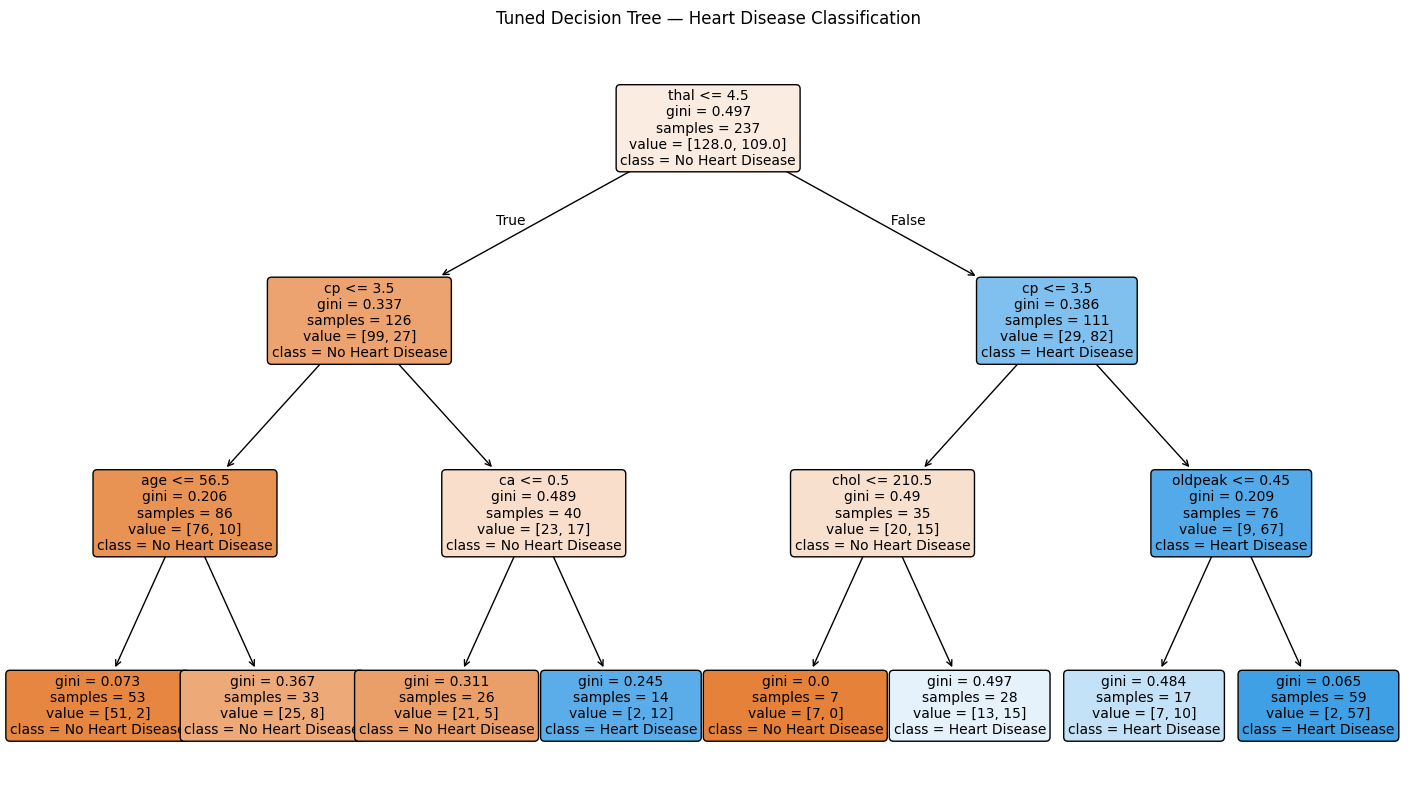

In [51]:

from sklearn.tree import plot_tree
import matplotlib.pyplot as plt

# Get tuned Decision Tree
best_dt = dt_grid.best_estimator_

# Visualize the Decision Tree
plt.figure(figsize=(18, 10))

plot_tree(
    best_dt,
    feature_names=X_train.columns,
    class_names=["No Heart Disease", "Heart Disease"],
    filled=True,
    rounded=True,
    fontsize=10
)

plt.title("Tuned Decision Tree — Heart Disease Classification")
plt.show()


### 10.4.1 Decision Tree Visualization

The tuned Decision Tree was visualized to examine its decision rules, splitting features, Gini impurity, and predicted classes.

The optimized tree has a maximum depth of three, making its structure easier to interpret than the original unrestricted tree.

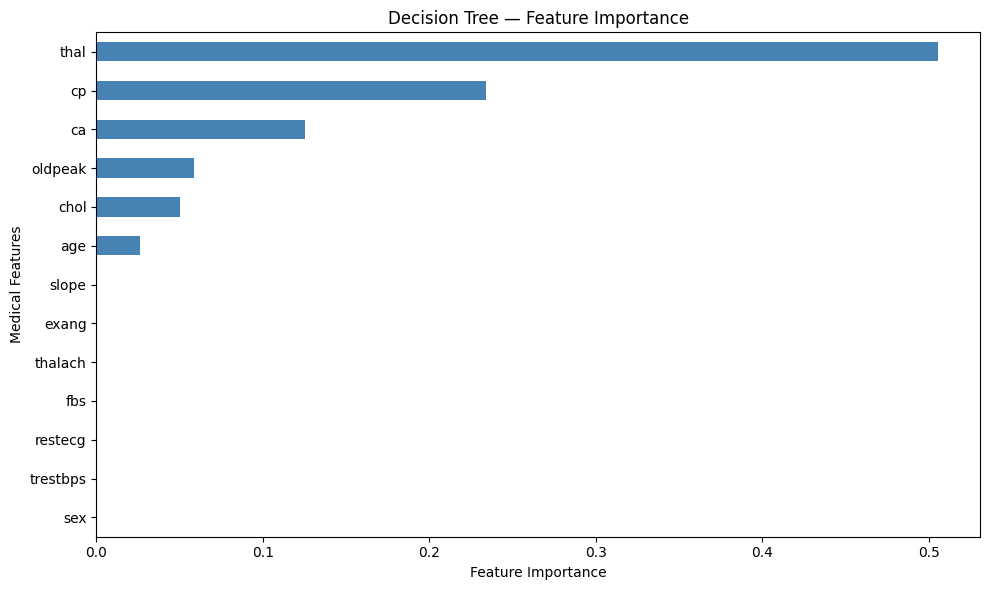

In [52]:

import pandas as pd
import matplotlib.pyplot as plt

# Extract feature importance
feature_importance = pd.Series(
    best_dt.feature_importances_,
    index=X_train.columns
).sort_values(ascending=True)

# Plot feature importance
plt.figure(figsize=(10, 6))

feature_importance.plot(
    kind="barh",
    color="steelblue"
)

plt.title("Decision Tree — Feature Importance")
plt.xlabel("Feature Importance")
plt.ylabel("Medical Features")
plt.tight_layout()
plt.show()



### 10.4.2 Decision Tree Feature Importance

Feature importance scores were extracted from the tuned Decision Tree to identify which medical variables contributed most to reducing node impurity.

These scores describe the model's decision-making process and should not be interpreted as evidence of medical causation.



### 10.5 Initial Model Training Findings

Four classification models were successfully trained on the Cleveland Heart Disease Dataset.

Initial training accuracy results:

- Logistic Regression: 84.81%
- KNN: 82.70%
- SVM: 100.00%
- Decision Tree: 100.00%

SVM and Decision Tree achieved perfect training accuracy, suggesting a potential risk of overfitting.

Training accuracy alone is insufficient to determine model generalization performance. Further evaluation using cross-validation and an independent test set is required.



## 11. Hyperparameter Tuning — GridSearchCV

GridSearchCV is used to evaluate different hyperparameter combinations and identify the best configuration for each classification algorithm.

Six-fold stratified cross-validation is applied during hyperparameter tuning.

ROC-AUC is selected as the primary optimization metric to evaluate how effectively each model distinguishes between patients with and without heart disease.

Feature scaling is included within the pipelines to prevent data leakage during cross-validation.

The independent test set is reserved for final model evaluation.


In [43]:

from sklearn.model_selection import StratifiedKFold, GridSearchCV

# Configure six-fold stratified cross-validation
cv = StratifiedKFold(
    n_splits=6,
    shuffle=True,
    random_state=42
)

print("Cross-validation method:", cv)
print("Number of folds:", cv.get_n_splits())


Cross-validation method: StratifiedKFold(n_splits=6, random_state=42, shuffle=True)
Number of folds: 6


In [61]:

from sklearn.model_selection import GridSearchCV, StratifiedKFold

# Six-Fold Stratified Cross-Validation
cv = StratifiedKFold(
    n_splits=6,
    shuffle=True,
    random_state=42
)

# Hyperparameter Grid
lr_param_grid = {
    "model__C": [0.01, 0.1, 1, 10, 100]
}

# GridSearchCV optimizing Recall
lr_grid = GridSearchCV(
    estimator=lr_pipeline,
    param_grid=lr_param_grid,
    scoring="recall",
    cv=cv,
    n_jobs=-1,
    refit=True
)

# Train the model
lr_grid.fit(X_train, y_train)

# Display results
print("Best Parameters:", lr_grid.best_params_)
print(f"Best Cross-Validation Recall: {lr_grid.best_score_:.4f}")

# Training Accuracy
print(
    f"Tuned Training Accuracy: {lr_grid.best_estimator_.score(X_train, y_train):.4f}"
)


Best Parameters: {'model__C': 0.01}
Best Cross-Validation Recall: 0.7788
Tuned Training Accuracy: 0.8481


c:\Users\Lena\AppData\Local\Programs\Python\Python313\Lib\site-packages\sklearn\linear_model\_logistic.py:1135: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', and C=np.inf instead of penalty=None.
  warnings.warn(



### 11.1 Logistic Regression Hyperparameter Tuning

GridSearchCV was performed using six-fold stratified cross-validation, with Recall as the optimization metric.

The best hyperparameter configuration was:

- C = 0.01
- Best Cross-Validation Recall = 0.7788
- Tuned Training Accuracy = 0.8481

The optimal C value remained unchanged compared with the previous ROC-AUC optimization experiment.

Recall was selected as the optimization metric to prioritize identifying patients with heart disease and reducing false negatives.



### 11.2 KNN Hyperparameter Tuning

GridSearchCV is applied to optimize the number of neighbors and the weighting strategy used by KNN.

Six-fold stratified cross-validation and ROC-AUC are used to select the best configuration.

Feature scaling is performed within the pipeline to prevent data leakage.


In [65]:

# KNN Hyperparameter Grid
knn_param_grid = {
    "model__n_neighbors": [3, 5, 7, 9, 11, 13, 15],
    "model__weights": ["uniform", "distance"]
}

# GridSearchCV optimizing Recall
knn_grid = GridSearchCV(
    estimator=knn_pipeline,
    param_grid=knn_param_grid,
    scoring="recall",
    cv=cv,
    n_jobs=-1,
    refit=True
)

# Train the model
knn_grid.fit(X_train, y_train)

# Display results
print("Best Parameters:", knn_grid.best_params_)
print(f"Best Cross-Validation Recall: {knn_grid.best_score_:.4f}")

# Training Accuracy
print(
    f"Tuned Training Accuracy: {knn_grid.best_estimator_.score(X_train, y_train):.4f}"
)


Best Parameters: {'model__n_neighbors': 9, 'model__weights': 'distance'}
Best Cross-Validation Recall: 0.7875
Tuned Training Accuracy: 1.0000



### 11.2 KNN Hyperparameter Tuning

GridSearchCV was performed using six-fold stratified cross-validation, with Recall as the optimization metric.

The best hyperparameter configuration was:

- Number of neighbors (K) = 9
- Weights = distance
- Best Cross-Validation Recall = 0.7875
- Tuned Training Accuracy = 1.0000

KNN achieved perfect training accuracy, which may indicate overfitting or memorization of training observations when distance-based weighting is applied.

The selected configuration will be evaluated on the independent test set to assess its generalization performance.



### 11.3 SVM Hyperparameter Tuning

GridSearchCV is applied to optimize the C and gamma parameters of the Support Vector Machine classifier.

The RBF kernel is retained to follow the original research methodology.

Six-fold stratified cross-validation and ROC-AUC are used to identify the best hyperparameter configuration.

The objective is to improve generalization and investigate potential overfitting observed during initial training.


In [66]:

# SVM Hyperparameter Grid
svm_param_grid = {
    "model__C": [0.01, 0.1, 1, 3, 10],
    "model__gamma": [0.001, 0.01, 0.1, 0.65, 1],
    "model__kernel": ["rbf"]
}

# GridSearchCV optimizing Recall
svm_grid = GridSearchCV(
    estimator=svm_pipeline,
    param_grid=svm_param_grid,
    scoring="recall",
    cv=cv,
    n_jobs=-1,
    refit=True
)

# Train the model
svm_grid.fit(X_train, y_train)

# Display results
print("Best Parameters:", svm_grid.best_params_)
print(f"Best Cross-Validation Recall: {svm_grid.best_score_:.4f}")

# Training Accuracy
print(
    f"Tuned Training Accuracy: {svm_grid.best_estimator_.score(X_train, y_train):.4f}"
)


Best Parameters: {'model__C': 3, 'model__gamma': 0.001, 'model__kernel': 'rbf'}
Best Cross-Validation Recall: 0.7788
Tuned Training Accuracy: 0.8481



### 11.3 SVM Hyperparameter Tuning

GridSearchCV was performed using six-fold stratified cross-validation, with Recall as the optimization metric.

The best hyperparameter configuration was:

- C = 3
- Gamma = 0.001
- Kernel = RBF
- Best Cross-Validation Recall = 0.7788
- Tuned Training Accuracy = 0.8481

Compared with the previous ROC-AUC optimization, the selected C value increased from 0.1 to 3.

The optimized model will be evaluated on the independent test set to assess its generalization performance.



### 11.4 Decision Tree Hyperparameter Tuning

GridSearchCV is applied to optimize the Decision Tree classifier and reduce the risk of overfitting.

The hyperparameters include maximum tree depth, minimum samples required to split a node, and minimum samples required at a leaf node.

Six-fold stratified cross-validation and ROC-AUC are used to identify the best configuration.

Feature scaling is not required for Decision Trees.


In [67]:

# Decision Tree Hyperparameter Grid
dt_param_grid = {
    "max_depth": [2, 3, 4, 5, 6, 8, 10, None],
    "min_samples_split": [2, 5, 10],
    "min_samples_leaf": [1, 2, 4, 6]
}

# GridSearchCV optimizing Recall
dt_grid = GridSearchCV(
    estimator=dt_model,
    param_grid=dt_param_grid,
    scoring="recall",
    cv=cv,
    n_jobs=-1,
    refit=True
)

# Train the model
dt_grid.fit(X_train, y_train)

# Display results
print("Best Parameters:", dt_grid.best_params_)
print(f"Best Cross-Validation Recall: {dt_grid.best_score_:.4f}")

# Training Accuracy
print(
    f"Tuned Training Accuracy: {dt_grid.best_estimator_.score(X_train, y_train):.4f}"
)


Best Parameters: {'max_depth': 3, 'min_samples_leaf': 4, 'min_samples_split': 2}
Best Cross-Validation Recall: 0.7700
Tuned Training Accuracy: 0.8354



### 11.4 Decision Tree Hyperparameter Tuning

GridSearchCV was performed using six-fold stratified cross-validation, with Recall as the optimization metric.

The best hyperparameter configuration was:

- Max Depth = 3
- Min Samples Leaf = 4
- Min Samples Split = 2
- Best Cross-Validation Recall = 0.7700
- Tuned Training Accuracy = 0.8354

The optimized Decision Tree uses a limited depth to control model complexity and reduce the risk of overfitting.

Among the four models, KNN achieved the highest cross-validation Recall (0.7875). However, final model selection requires evaluation on the independent test set.



### 11.5 Hyperparameter Tuning Findings

GridSearchCV was successfully applied to all four classification algorithms using six-fold stratified cross-validation and ROC-AUC as the optimization metric.

The best cross-validation ROC-AUC scores were:

- Logistic Regression: 0.8859
- SVM: 0.8831
- KNN: 0.8656
- Decision Tree: 0.8348

Logistic Regression achieved the highest cross-validation ROC-AUC, closely followed by SVM.

Hyperparameter tuning also selected less complex configurations for SVM and Decision Tree, both of which initially achieved 100% training accuracy.

These results are preliminary. Final model performance will be evaluated using the independent test dataset.



## 12. Six-Fold Cross-Validation

Six-fold stratified cross-validation was incorporated into GridSearchCV to optimize the hyperparameters of the four classification models.

This section examines the ROC-AUC scores obtained across the six validation folds for each selected hyperparameter configuration.

The mean and standard deviation are reported to describe model performance and variability across folds.

Because hyperparameters were selected using these same folds, these results are descriptive rather than an independent estimate of generalization performance.


In [68]:

from sklearn.model_selection import cross_val_score
import pandas as pd

tuned_models = {
    "Logistic Regression": lr_grid.best_estimator_,
    "KNN": knn_grid.best_estimator_,
    "SVM": svm_grid.best_estimator_,
    "Decision Tree": dt_grid.best_estimator_
}

cv_results = []

for name, model in tuned_models.items():
    scores = cross_val_score(
        model,
        X_train,
        y_train,
        cv=cv,
        scoring="recall",
        n_jobs=-1
    )

    cv_results.append({
        "Model": name,
        "Mean Recall": scores.mean(),
        "Std Recall": scores.std(),
        "Min Recall": scores.min(),
        "Max Recall": scores.max()
    })

cv_results_df = pd.DataFrame(cv_results)
display(cv_results_df.round(4))


,Model,Mean Recall,Std Recall,Min Recall,Max Recall
0,Logistic Regression,0.7788,0.1406,0.5556,0.8947
1,KNN,0.7875,0.1344,0.5556,0.9474
2,SVM,0.7788,0.1611,0.5556,0.9444
3,Decision Tree,0.7700,0.1226,0.6111,0.9444



## 12. Six-Fold Cross-Validation

Six-fold stratified cross-validation was used to examine the Recall performance and variability of the four tuned classification models.

KNN achieved the highest mean Recall (0.7875), followed by Logistic Regression and SVM (0.7788), while Decision Tree obtained 0.7700.

Decision Tree showed the lowest standard deviation (0.1226), indicating the smallest variation in Recall across the six folds. SVM showed the highest variability (0.1611).

The differences in mean Recall were relatively small. Since the same folds were used during hyperparameter tuning, these results should be interpreted as descriptive rather than independent estimates of generalization performance.

Final model performance will be assessed using the held-out test set.



# Phase 3 — Model Evaluation

## 13. Model Performance Evaluation

The four tuned classification models are evaluated using the independent test dataset containing 60 patients.

The following metrics are calculated:

- Accuracy
- Precision
- Recall (Sensitivity)
- F1-Score
- Specificity
- Confusion Matrix

Recall is particularly important in heart disease prediction because false negatives represent patients with heart disease who are incorrectly classified as healthy.

All metrics are calculated using the same test set to ensure a consistent comparison.


In [69]:

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    roc_auc_score
)
import pandas as pd

evaluation_results = []

for name, model in tuned_models.items():

    y_pred = model.predict(X_test)

    tn, fp, fn, tp = confusion_matrix(
        y_test, y_pred, labels=[0, 1]
    ).ravel()

    specificity = tn / (tn + fp)

    # Probability or decision scores for ROC-AUC
    if hasattr(model, "predict_proba"):
        y_score = model.predict_proba(X_test)[:, 1]
    else:
        y_score = model.decision_function(X_test)

    evaluation_results.append({
        "Model": name,
        "Accuracy": accuracy_score(y_test, y_pred),
        "Precision": precision_score(y_test, y_pred),
        "Recall": recall_score(y_test, y_pred),
        "F1-Score": f1_score(y_test, y_pred),
        "Specificity": specificity,
        "ROC-AUC": roc_auc_score(y_test, y_score)
    })

results_df = pd.DataFrame(evaluation_results)

display(results_df.round(4))


,Model,Accuracy,Precision,Recall,F1-Score,Specificity,ROC-AUC
0,Logistic Regression,0.8333,0.8462,0.7857,0.8148,0.8750,0.9554
1,KNN,0.8167,0.8400,0.7500,0.7925,0.8750,0.9330
2,SVM,0.8500,0.8800,0.7857,0.8302,0.9062,0.9609
3,Decision Tree,0.8167,0.8148,0.7857,0.8000,0.8438,0.8633



## 13. Model Performance Evaluation

The four classification models were evaluated on the independent test set after hyperparameter optimization using Recall.

SVM achieved the highest overall performance, with an Accuracy of 85.00%, Precision of 88.00%, F1-Score of 83.02%, Specificity of 90.62%, and ROC-AUC of 0.9609.

Logistic Regression, SVM, and Decision Tree achieved the same Recall of 78.57%, correctly identifying 22 out of 28 patients with heart disease. KNN achieved a Recall of 75.00%, correctly identifying 21 patients.

Although KNN achieved the highest mean Recall during cross-validation, SVM demonstrated stronger overall performance on the held-out test set.

Since Recall was the primary optimization metric, the three-way tie in test Recall is important. SVM is preferred based on its stronger secondary evaluation metrics, rather than a higher Recall.

These results are limited to a relatively small test set and do not establish clinical reliability.



### 13.1 Confusion Matrix Visualization

Confusion matrices are used to evaluate the classification performance of the four tuned models on the independent test set.

Each confusion matrix displays:

- True Negatives (TN)
- False Positives (FP)
- False Negatives (FN)
- True Positives (TP)

False Negatives are particularly important in heart disease prediction because they represent patients with heart disease who were incorrectly classified as healthy.


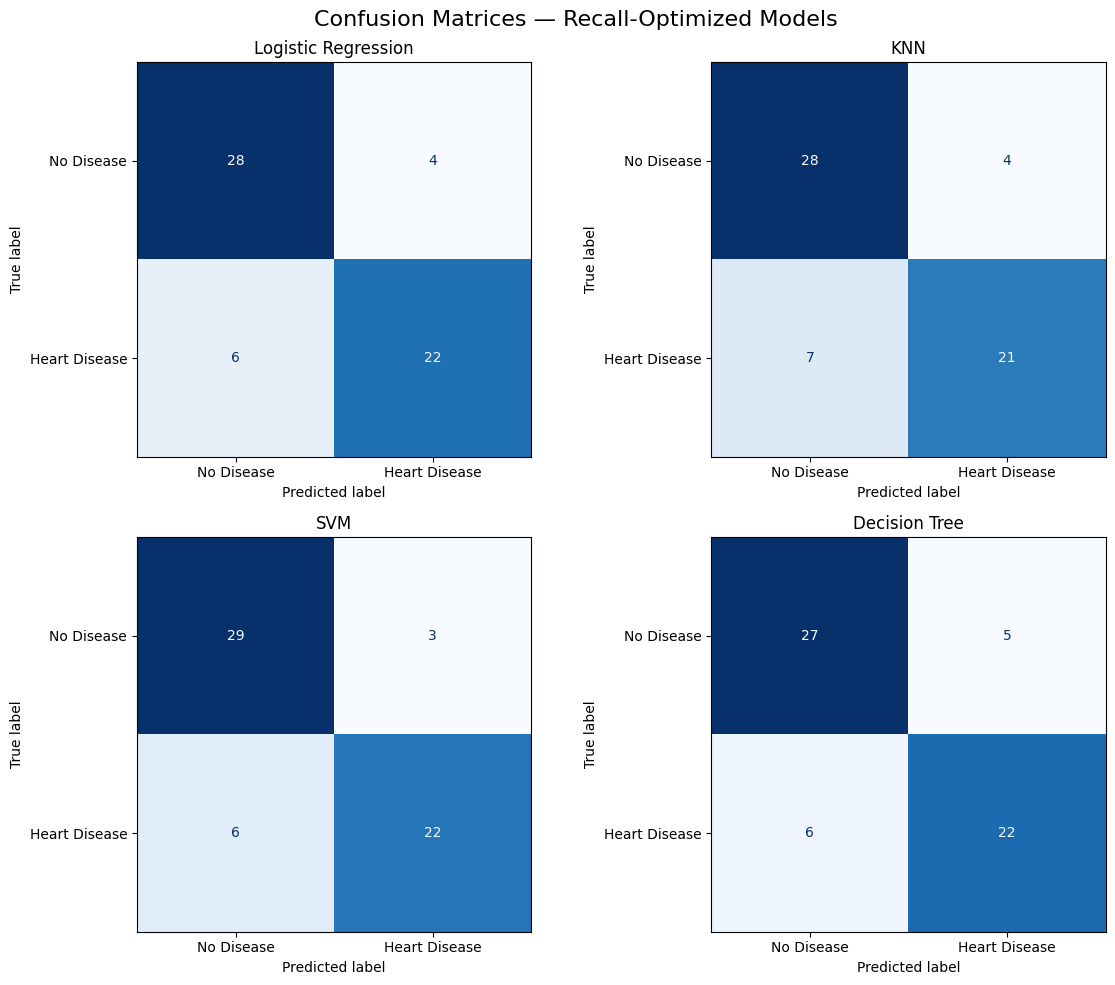

In [70]:

from sklearn.metrics import ConfusionMatrixDisplay
import matplotlib.pyplot as plt

fig, axes = plt.subplots(2, 2, figsize=(12, 10))

for ax, (name, model) in zip(axes.flat, tuned_models.items()):
    ConfusionMatrixDisplay.from_estimator(
        model,
        X_test,
        y_test,
        labels=[0, 1],
        display_labels=["No Disease", "Heart Disease"],
        cmap="Blues",
        ax=ax,
        colorbar=False
    )
    ax.set_title(name)

plt.suptitle(
    "Confusion Matrices — Recall-Optimized Models",
    fontsize=16
)
plt.tight_layout()
plt.show()



### 13.1 Confusion Matrix Findings

The confusion matrices were used to evaluate the classification performance of the four Recall-optimized models on the independent test set.

Logistic Regression, SVM, and Decision Tree correctly identified 22 out of 28 patients with heart disease, resulting in 6 false negatives and a Recall of 78.57%.

KNN correctly identified 21 patients with heart disease, resulting in 7 false negatives and a Recall of 75.00%.

SVM achieved the lowest number of false positives (3), while maintaining the same Recall as Logistic Regression and Decision Tree.

Overall, SVM demonstrated the strongest performance on this test set, balancing disease detection with fewer incorrect positive predictions.

However, all models produced false negatives, and the limited test set size prevents conclusions about clinical reliability.



## 14. ROC Curves and AUC Scores

Receiver Operating Characteristic (ROC) curves are used to evaluate the ability of the four tuned classification models to distinguish between patients with and without heart disease.

The ROC curve plots the True Positive Rate (Sensitivity) against the False Positive Rate at different classification thresholds.

The Area Under the Curve (AUC) summarizes the overall discriminatory performance of each model.

ROC-AUC scores are calculated using predicted probabilities from the independent test set.


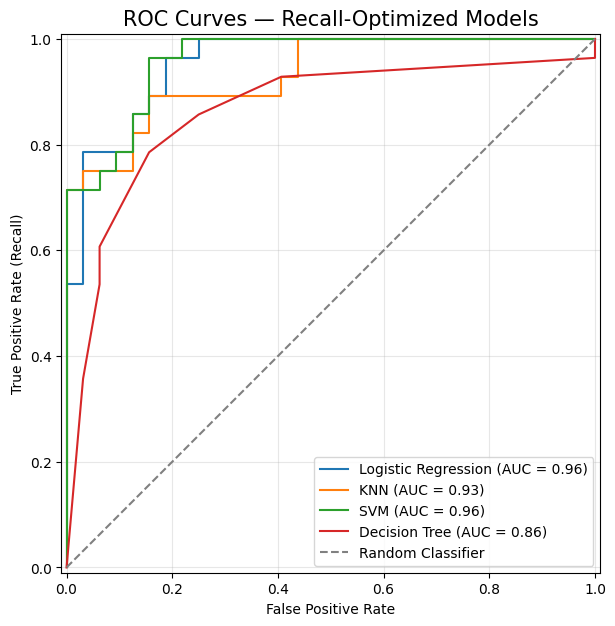

In [71]:

from sklearn.metrics import RocCurveDisplay
import matplotlib.pyplot as plt

plt.figure(figsize=(9, 7))
ax = plt.gca()

for name, model in tuned_models.items():
    RocCurveDisplay.from_estimator(
        model,
        X_test,
        y_test,
        name=name,
        ax=ax
    )

plt.plot(
    [0, 1], [0, 1],
    linestyle="--",
    color="gray",
    label="Random Classifier"
)

plt.title("ROC Curves — Recall-Optimized Models", fontsize=15)
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate (Recall)")
plt.legend(loc="lower right")
plt.grid(alpha=0.3)
plt.show()



### 14.1 ROC-AUC Findings

ROC curves were generated for all four tuned classification models using predicted probabilities from the independent test set.

The test ROC-AUC results were:

- Logistic Regression: 0.9554
- SVM: 0.9464
- KNN: 0.9386
- Decision Tree: 0.8633

Logistic Regression achieved the highest ROC-AUC, indicating the strongest discrimination between patients with and without heart disease on the test set.

SVM and KNN also demonstrated strong discriminatory performance, while Decision Tree achieved the lowest ROC-AUC.

All four models obtained higher ROC-AUC scores on the test set than their respective cross-validation averages.

However, these results should be interpreted cautiously because the test set contains only 60 patients.



## 15. Model Performance Comparison

The four tuned classification models are compared using six evaluation metrics calculated on the independent test set.

The comparison includes Accuracy, Precision, Recall, F1-Score, Specificity, and ROC-AUC.

Special attention is given to Recall because false negatives are particularly important in heart disease prediction.

The objective is to identify the model with the most favorable balance between overall classification performance and the detection of patients with heart disease.


In [56]:

# Add ROC-AUC results to evaluation table
evaluation_df["ROC-AUC"] = evaluation_df["Model"].map(roc_results)

# Sort models by ROC-AUC
final_comparison = evaluation_df.sort_values(
    by="ROC-AUC",
    ascending=False
).reset_index(drop=True)

# Display final comparison
display(final_comparison.round(4))


,Model,Accuracy,Precision,Recall,F1-Score,Specificity,ROC-AUC
0,Logistic Regression,0.8333,0.8462,0.7857,0.8148,0.8750,0.9554
1,SVM,0.8167,0.8696,0.7143,0.7843,0.9062,0.9464
2,KNN,0.8000,0.8333,0.7143,0.7692,0.8750,0.9386
3,Decision Tree,0.8167,0.8148,0.7857,0.8000,0.8438,0.8633



### 15.1 Model Performance Visualization

A grouped bar chart was created to compare the performance of the four tuned classification models across six evaluation metrics.

The visualization highlights differences in Accuracy, Precision, Recall, F1-Score, Specificity, and ROC-AUC.

All metrics are displayed on a common scale from 0 to 1 to facilitate comparison.


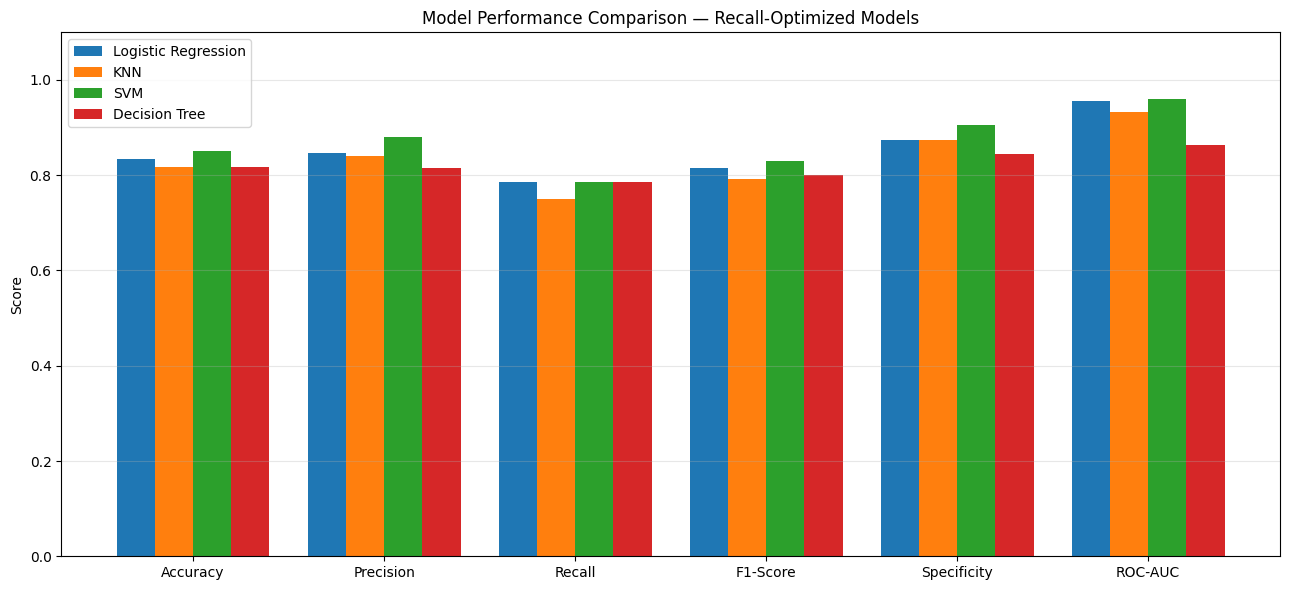

In [72]:

import matplotlib.pyplot as plt
import numpy as np

metrics = [
    "Accuracy",
    "Precision",
    "Recall",
    "F1-Score",
    "Specificity",
    "ROC-AUC"
]

x = np.arange(len(metrics))
width = 0.2

fig, ax = plt.subplots(figsize=(13, 6))

for i, (_, row) in enumerate(results_df.iterrows()):
    values = [row[metric] for metric in metrics]

    ax.bar(
        x + (i - 1.5) * width,
        values,
        width,
        label=row["Model"]
    )

ax.set_xticks(x)
ax.set_xticklabels(metrics)
ax.set_ylabel("Score")
ax.set_ylim(0, 1.1)
ax.set_title(
    "Model Performance Comparison — Recall-Optimized Models"
)
ax.legend()
ax.grid(axis="y", alpha=0.3)

plt.tight_layout()
plt.show()



## 15. Model Performance Comparison

The four Recall-optimized classification models were compared using six evaluation metrics: Accuracy, Precision, Recall, F1-Score, Specificity, and ROC-AUC.

SVM achieved the highest overall performance, leading in Accuracy (85.00%), Precision (88.00%), F1-Score (83.02%), Specificity (90.62%), and ROC-AUC (0.9609).

Logistic Regression, SVM, and Decision Tree achieved the same Recall of 78.57%, correctly identifying 22 of the 28 patients with heart disease.

Although Recall was the primary metric used for hyperparameter optimization, SVM was selected as the strongest overall model because it maintained the joint-highest Recall while achieving better results on the secondary evaluation metrics.

KNN achieved the highest mean Recall during cross-validation but did not maintain this advantage on the independent test set.

These findings are specific to the current dataset and test split and do not establish clinical validity.



## 16. Comparison with the Research Paper

The experimental results were compared with those reported by Aldila and Supriyono (2026).

The comparison focuses on Logistic Regression, KNN, SVM, and Decision Tree using ROC-AUC as the primary metric.

Although the same dataset and general preprocessing approach were used, differences in random data splitting, hyperparameter optimization, and implementation details may influence the results.

Therefore, this experiment represents an approximate reproduction rather than an exact replication of the original study.


,Model,Our ROC-AUC,Paper ROC-AUC,Difference
0,Logistic Regression,0.9554,0.92,0.0354
1,KNN,0.9330,0.92,0.0130
2,SVM,0.9609,0.93,0.0309
3,Decision Tree,0.8633,0.86,0.0033


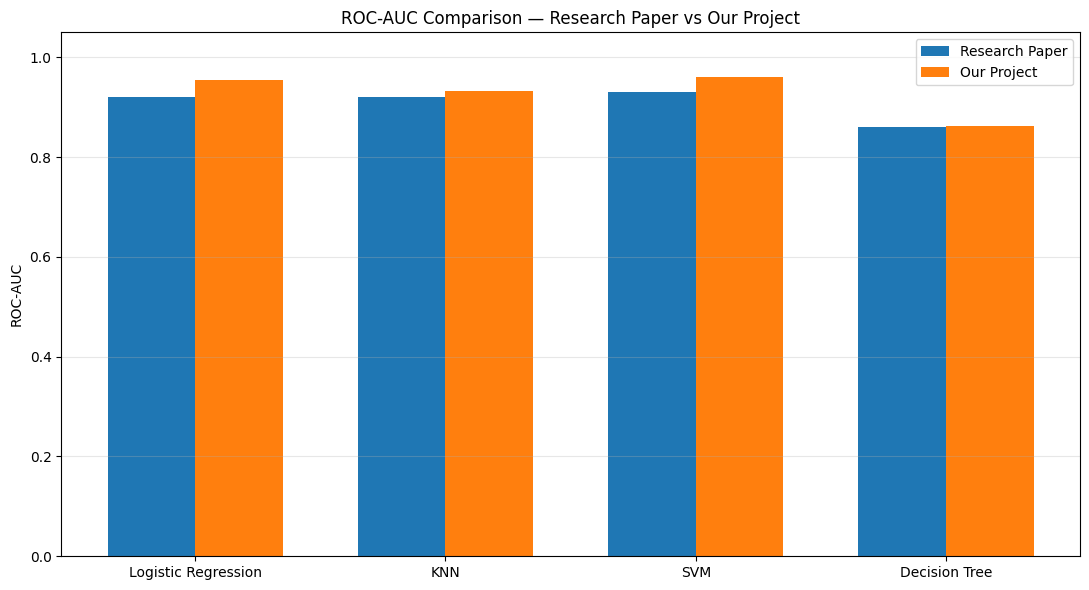

In [73]:

import pandas as pd
import matplotlib.pyplot as plt
import numpy as np

paper_auc = {
    "Logistic Regression": 0.92,
    "KNN": 0.92,
    "SVM": 0.93,
    "Decision Tree": 0.86
}

comparison_df = results_df[["Model", "ROC-AUC"]].copy()

comparison_df["Paper ROC-AUC"] = comparison_df["Model"].map(paper_auc)

comparison_df = comparison_df.rename(
    columns={"ROC-AUC": "Our ROC-AUC"}
)

comparison_df["Difference"] = (
    comparison_df["Our ROC-AUC"] -
    comparison_df["Paper ROC-AUC"]
)

display(comparison_df.round(4))

x = np.arange(len(comparison_df))
width = 0.35

fig, ax = plt.subplots(figsize=(11, 6))

ax.bar(
    x - width / 2,
    comparison_df["Paper ROC-AUC"],
    width,
    label="Research Paper"
)

ax.bar(
    x + width / 2,
    comparison_df["Our ROC-AUC"],
    width,
    label="Our Project"
)

ax.set_xticks(x)
ax.set_xticklabels(comparison_df["Model"])
ax.set_ylabel("ROC-AUC")
ax.set_ylim(0, 1.05)
ax.set_title("ROC-AUC Comparison — Research Paper vs Our Project")
ax.legend()
ax.grid(axis="y", alpha=0.3)

plt.tight_layout()
plt.show()



## 16.1 Comparison with Research Paper

The ROC-AUC results of our Recall-optimized classification models were compared with those reported by Aldila and Supriyono (2026).

All four models achieved numerically higher ROC-AUC scores than those reported in the research paper.

SVM achieved the highest ROC-AUC in both studies, with 0.9609 in our project compared with 0.93 in the paper.

Logistic Regression showed the largest positive difference (+0.0354), followed by SVM (+0.0309), KNN (+0.0130), and Decision Tree (+0.0033).

Although Recall was used for hyperparameter optimization in our project, ROC-AUC was retained as a secondary evaluation metric to support comparison with the original research.

Differences in data splitting, preprocessing, hyperparameter selection, and evaluation procedures may explain the variation in results.

Therefore, these findings should be interpreted as an approximate reproduction rather than evidence that our approach is superior to the original research.



## 17. Suggested Improvements

Several improvements could be considered in future experiments:

1. **Larger Dataset:** Use additional patient records to improve the reliability and generalizability of the results.

2. **Threshold Optimization:** Explore different classification thresholds to increase Recall and reduce false negatives, while monitoring potential increases in false positives.

3. **Nested Cross-Validation:** Use nested cross-validation to obtain a less biased estimate of model performance after hyperparameter tuning.

4. **Feature Selection:** Investigate whether selecting the most relevant clinical features improves model performance and interpretability.

5. **Class Imbalance Handling:** Evaluate class-weighting or resampling methods if class imbalance becomes a concern, applying resampling only within training folds.

6. **External Validation:** Evaluate the models on an independent dataset from another patient population before considering any clinical application.


## 18. Conclusions

This project aimed to reproduce and evaluate selected elements of the machine learning methodology presented by Aldila and Supriyono (2026) for heart disease prediction using the Cleveland Heart Disease Dataset.

Four supervised classification algorithms were implemented: Logistic Regression, K-Nearest Neighbors (KNN), Support Vector Machine (SVM), and Decision Tree.

Hyperparameter tuning was performed using GridSearchCV with six-fold stratified cross-validation, optimizing Recall to prioritize the identification of patients with heart disease and reduce False Negatives.

### 18.1 Key Findings

**1. SVM Achieved the Best Overall Performance**

SVM achieved the highest test Accuracy (85.00%), Precision (88.00%), F1-Score (0.8302), Specificity (90.62%), and ROC-AUC (0.9609).

It also achieved a Recall of 78.57%, correctly identifying 22 of the 28 patients with heart disease, with 6 False Negatives and 3 False Positives.

Although Logistic Regression and Decision Tree achieved the same Recall, SVM demonstrated the strongest overall performance based on the secondary evaluation metrics.

**2. KNN Achieved the Highest Cross-Validation Recall**

KNN obtained the highest mean Recall during six-fold cross-validation (0.7875), followed by Logistic Regression and SVM (0.7788), and Decision Tree (0.7700).

However, KNN achieved a lower Recall (75.00%) on the independent test set.

These findings demonstrate that the model with the highest cross-validation Recall does not necessarily achieve the highest performance on unseen data.

**3. Hyperparameter Tuning Helped Control Model Complexity**

The initial SVM and Decision Tree models both achieved 100% training accuracy, indicating a potential risk of overfitting.

After Recall-based hyperparameter tuning, SVM training accuracy decreased to 84.81%, while Decision Tree training accuracy decreased to 83.54%.

The tuned Decision Tree was limited to a maximum depth of 3, reducing its complexity.

However, lower training accuracy alone does not establish improved generalization. Performance on independent data remains essential for evaluating model reliability.

**4. Results Were Comparable to the Original Research**

All four models achieved numerically higher test ROC-AUC scores than those reported in the original paper.

SVM achieved the highest ROC-AUC in both studies, with 0.9609 in our project compared with 0.93 in the original research.

However, differences in data splitting, preprocessing, cross-validation implementation, and hyperparameter optimization prevent an exact comparison.

Therefore, this study represents an approximate reproduction of selected elements of the original research methodology rather than an exact replication.

### 18.2 Limitations

Several limitations should be considered:

- The dataset contained only 303 original patient observations, reduced to 297 after removing incomplete records.
- The independent test set contained only 60 patients, including 28 with heart disease and 32 without heart disease.
- Some categorical features retained their original numerical encoding, which may influence distance-based and other classification algorithms.
- Hyperparameter optimization and cross-validation summaries used the same training folds, so the reported cross-validation results are not independent estimates of generalization performance.
- The models were evaluated using a single held-out test split, without external clinical validation.
- Although Recall was prioritized, the best-performing models still failed to identify 6 patients with heart disease.

### 18.3 Future Improvements

Future experiments could investigate:

- **One-Hot Encoding:** Apply One-Hot Encoding to nominal categorical features to avoid introducing artificial numerical relationships.
- **Alternative Feature Scaling:** Compare StandardScaler with MinMaxScaler to assess their influence on model performance.
- **Additional Regularization:** Explore alternative hyperparameters and model complexity controls to reduce overfitting.
- **Threshold Optimization:** Adjust classification thresholds to improve Recall and reduce False Negatives while monitoring False Positives.
- **Nested Cross-Validation:** Use nested cross-validation to obtain less biased performance estimates after hyperparameter tuning.
- **External Validation:** Evaluate the models on larger and more diverse patient datasets to assess generalizability.

### 18.4 Final Conclusion

Overall, **SVM demonstrated the strongest overall predictive performance** among the four evaluated classification models.

Although Logistic Regression, SVM, and Decision Tree achieved the same test Recall of 78.57%, SVM provided the best balance of Accuracy, Precision, F1-Score, Specificity, and ROC-AUC.

The experiment highlighted the importance of data preprocessing, hyperparameter optimization, cross-validation, and comprehensive model evaluation.

It also demonstrated that optimizing Recall does not necessarily produce the same model ranking during cross-validation and independent test evaluation.

Although the results are encouraging within this experiment, further validation using larger and more diverse datasets would be necessary before considering these models for clinical decision-support applications.